# Big Play Board — Preseason Week 3 Field Map

Draws the week's longest plays as paths on a single 0–100 field.

**The one idea the whole chart rests on:** every yard line is expressed in the frame of
the team that *snapped* the ball. They attack toward 100. That means direction carries
meaning on its own —
- explosive offensive plays run **left to right**
- interceptions, fumbles, punt and kick returns run **right to left**, with a negative `net`

So a pick-six draws as a short forward stub hinged into a long backward sweep, and reads
as a pick-six before you've looked at a single colour or label.

Run the cells top to bottom. `fig` and `ax` are created once in the *Build the field*
section and every later cell draws onto them, so re-running a cell out of order will
double-draw. Restart and run all if things look smeared.

## 1. Imports and theme

`%matplotlib inline` registers Jupyter's PNG formatter for `Figure` objects, which is
what makes the bare `fig` at the end of later cells render as an image instead of the
plain `<Figure size ...>` repr.

`FancyArrowPatch` rather than `ax.arrow` because it keeps the arrowhead a fixed size in
points regardless of the data range. `ax.arrow` scales the head with the axes, so a
100-yard arrow and a 4-yard arrow would get wildly different heads.

In [13]:
%matplotlib inline
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, Rectangle
import matplotlib.pyplot as plt

from dataglazer_nfl.clients import espn
from dataglazer_nfl.clients.espn import PRESEASON


## 2. The Dataglazer style sheet

Applied straight from the package with `apply_style()`, which resolves
`src/dataglazer_nfl/viz/dataglazer.mplstyle` from the installed package rather than the
notebook's working directory — so there's no hand-copied stylesheet to keep in sync.
`BG`, `MUTED`, and `WHITE` come from `dataglazer_nfl.viz.palette`, which parses the same
file, so a stylesheet edit moves this chart with it too.

Font stack is Baloo 2 → Poppins → DejaVu Sans → Arial. Poppins is what actually resolves
in most environments, and it has **no arrow or geometric-shape glyphs**, so the couple of
strings below that use `→ ← ○` set `fontfamily="DejaVu Sans"` explicitly.

In [14]:
from dataglazer_nfl.viz.palette import BG, MUTED
from dataglazer_nfl.viz.palette import TEXT as WHITE
from dataglazer_nfl.viz.style import apply_style

apply_style()

FIELD   = "#26313C"   # playing surface, a touch lighter than the canvas
ENDZONE = "#2E3B48"   # end zones, lighter again

## 3. Fetch the data

Using `get_big_play_board` from the ESPN client. The function returns plays with
`segments` already in the snapping team's frame — the core transformation that makes
the chart readable. Each segment is `{from, to, kind, by, origin_source}`.

In [15]:
result = espn.get_big_play_board(
    week=3,
    year=2026,
    season_type=PRESEASON,
    top_n=12,
    include_returns=True
)

PLAYS = result["plays"]
print(f"{len(PLAYS)} plays (derived: {result['derived_count']})")

12 plays (derived: 2)


## 4. Picking a readable colour per team

Team colours are used rather than the brand palette because per-play identity matters
here, and direction already carries the offense/defense story.

The problem: six of these twelve teams have primaries too dark to read against a
`#1F2831` canvas, and three of those are near-identical navies. The fix is a WCAG
relative-luminance contrast ratio — try the primary, then the alternate, then lighten
whichever is closer toward white until it clears a ratio of 3.0.

Lightening rather than substituting matters. An earlier version fell back to brand cyan
and turned a third of the board the same colour, which destroyed exactly the identity the
team colours were there to provide. Goodson's muted rose and Maclin's red below are
lightened primaries, not different colours.

In [16]:
def _lin(c):
    """sRGB channel -> linear, per WCAG 2.x."""
    c = c / 255
    return c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4

def luminance(hexcolor):
    h = hexcolor.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return 0.2126 * _lin(r) + 0.7152 * _lin(g) + 0.0722 * _lin(b)

def contrast(a, b):
    """WCAG contrast ratio, 1.0 (identical) to 21.0 (black on white)."""
    la, lb = luminance(a), luminance(b)
    hi, lo = max(la, lb), min(la, lb)
    return (hi + 0.05) / (lo + 0.05)

def _mix(hexcolor, t):
    """Blend toward white by fraction t."""
    h = hexcolor.lstrip("#")
    rgb = [int(h[i:i + 2], 16) for i in (0, 2, 4)]
    return "#%02X%02X%02X" % tuple(round(c + (255 - c) * t) for c in rgb)

def pick_color(colors, threshold=3.0):
    primary, alt = colors["primary"], colors["alternate"]
    if contrast(primary, BG) >= threshold:
        return primary
    if contrast(alt, BG) >= threshold:
        return alt
    base = max((primary, alt), key=lambda c: contrast(c, BG))
    for t in (0.2, 0.35, 0.5, 0.65, 0.8):
        cand = _mix(base, t)
        if contrast(cand, BG) >= threshold:
            return cand
    return _mix(base, 0.8)

# what each team ends up with, and whether it needed adjusting
for p in PLAYS:
    chosen = pick_color(p["team_colors"])
    note = "primary" if chosen == p["team_colors"]["primary"] else (
        "alternate" if chosen == p["team_colors"]["alternate"] else "lightened")
    print(f'{p["team"]:>4}  {chosen}  ({note})')

 LAR  #FFD100  (alternate)
  SF  #B3995D  (alternate)
 HOU  #EB0028  (alternate)
 BUF  #DD3B3B  (lightened)
 DAL  #B0B7BC  (alternate)
  NE  #D13D59  (lightened)
 SEA  #69BE28  (alternate)
 WSH  #FFB612  (alternate)
 DAL  #B0B7BC  (alternate)
 DET  #0076B6  (primary)
 MIN  #FFC62F  (alternate)
 ATL  #C66A78  (lightened)


## 5. Build the field

Coordinate system is the useful trick here: **x is literally yard lines**, running -10 to
110 so the two end zones are real space rather than decoration. Arrow endpoints then come
straight from `segments` with no transform at all.

`xlim` runs out to -46 to open a gutter on the left for the player labels. That gutter
sits outside the field rectangle, so it reads as margin.

`ylim` is inverted (`n+0.4` down to `-1.5`) so row 0 — the longest play — lands at the
top. One row per play, one unit apart.

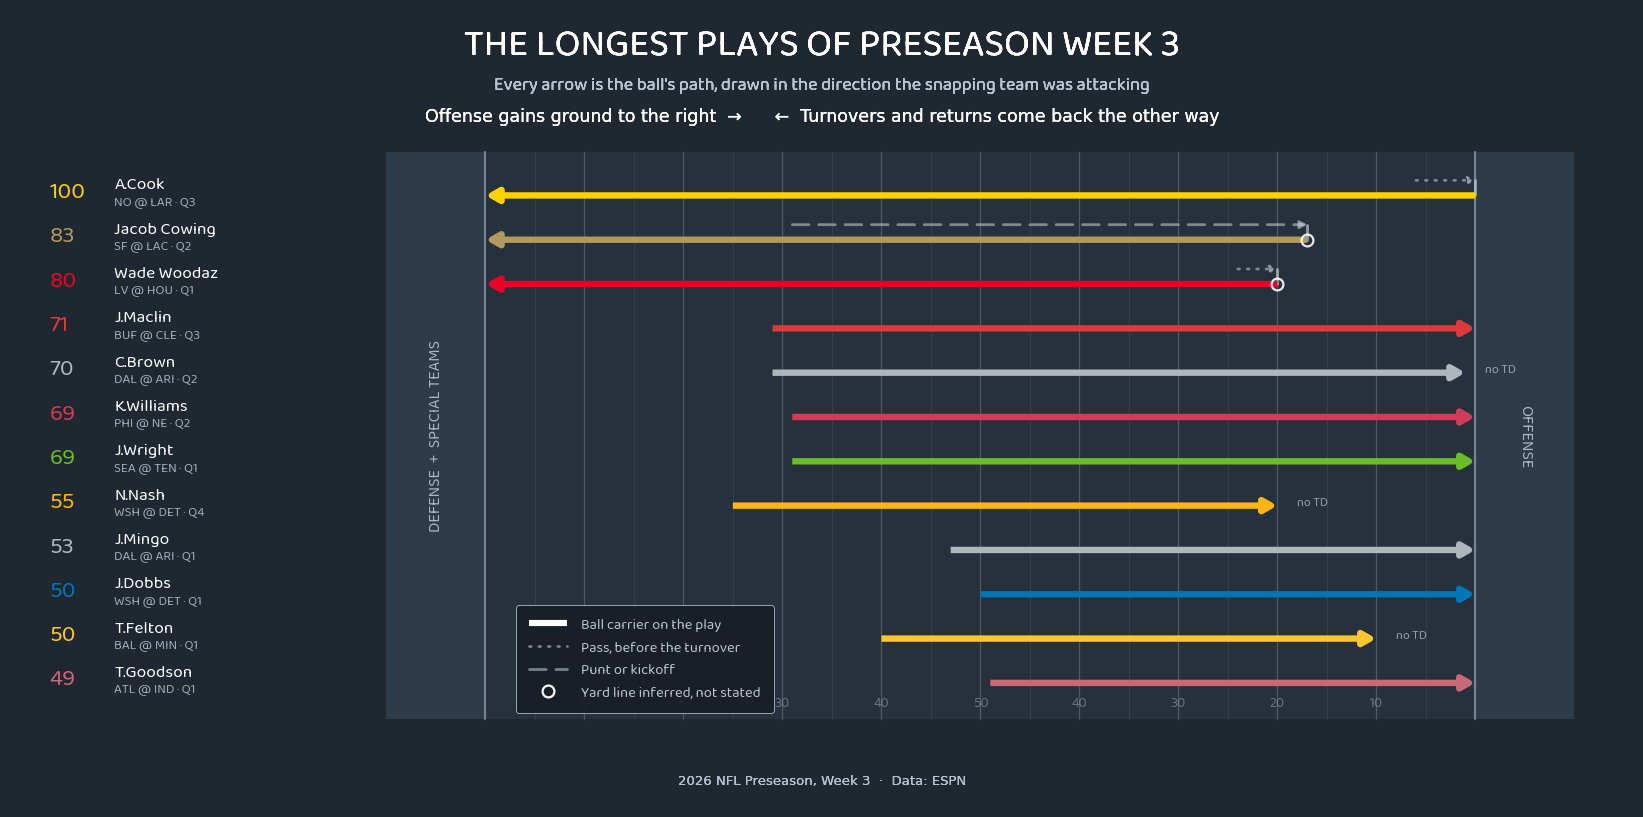

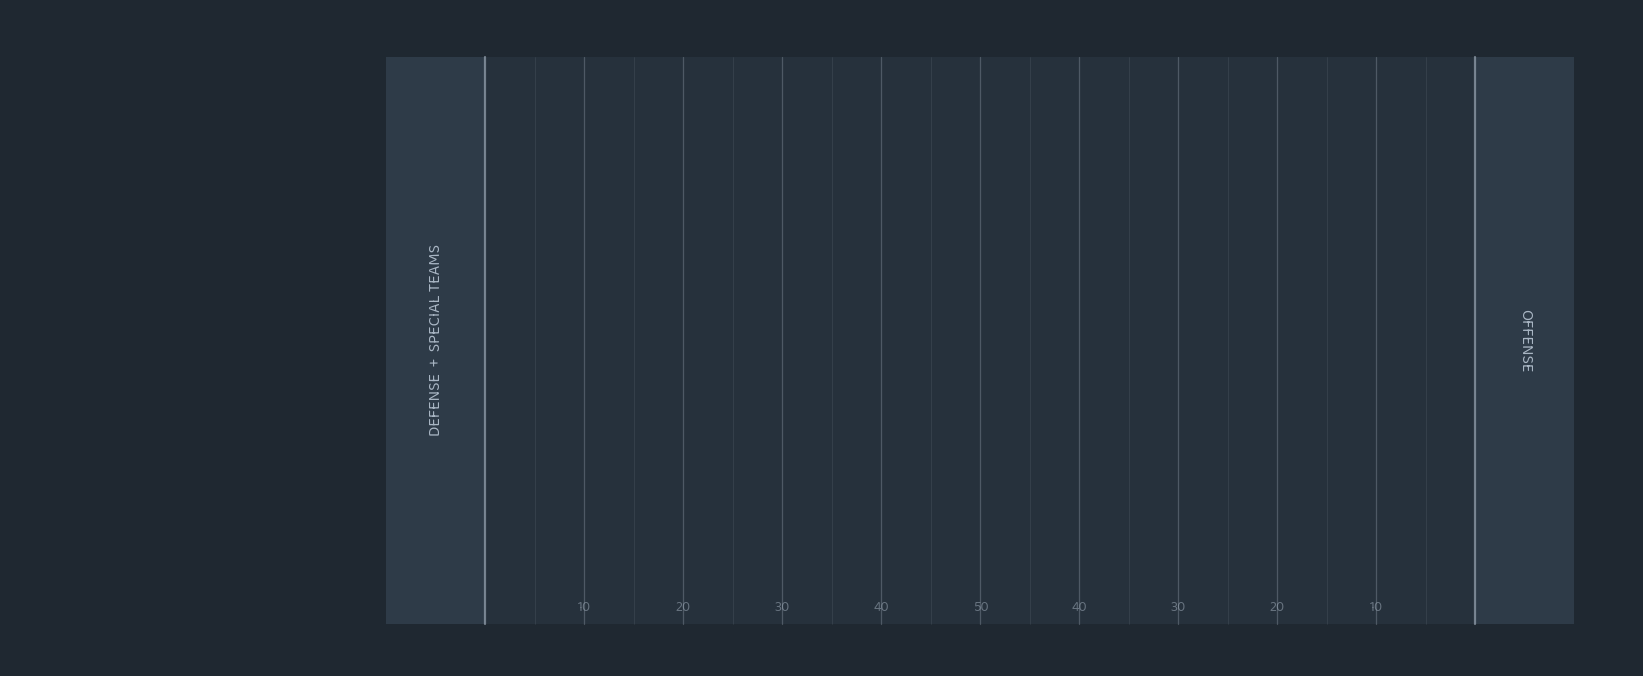

In [17]:
n = len(PLAYS)
LANE_H = 1.0
fig, ax = plt.subplots(figsize=(16, 8))          # 1600x800 at dpi=100
fig.subplots_adjust(left=0.005, right=0.995, top=0.845, bottom=0.075)
ax.set_xlim(-46, 114)
ax.set_ylim(n * LANE_H + 0.4, -1.5)              # inverted: biggest play on top
ax.set_facecolor(BG)
ax.set_xticks([])
ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)

top, bot = -0.9, n * LANE_H - 0.1

# playing surface and the two end zones
ax.add_patch(Rectangle((0, top), 100, bot - top, facecolor=FIELD, zorder=0))
ax.add_patch(Rectangle((-10, top), 10, bot - top, facecolor=ENDZONE, zorder=0))
ax.add_patch(Rectangle((100, top), 10, bot - top, facecolor=ENDZONE, zorder=0))

# yard lines every 5, emphasised every 10, goal lines brightest
for y in range(5, 100, 5):
    ax.plot([y, y], [top, bot], color=MUTED,
            lw=0.9 if y % 10 == 0 else 0.5,
            alpha=0.28 if y % 10 == 0 else 0.14, zorder=1)
for x in (0, 100):
    ax.plot([x, x], [top, bot], color=MUTED, lw=1.6, alpha=0.55, zorder=1)

# yard numbers count up to 50 then back down, like a real field
for y in range(10, 100, 10):
    ax.text(y, bot - 0.22, str(y if y <= 50 else 100 - y),
            ha="center", va="bottom", fontsize=10, color=MUTED, alpha=0.45)

# end-zone labels: these are what make the direction convention self-explanatory,
# so the reader never has to consult a legend to decode left vs right
ax.text(-5, (top + bot) / 2, "DEFENSE  +  SPECIAL TEAMS", rotation=90,
        ha="center", va="center", fontsize=11.5, fontweight="bold",
        color=MUTED, alpha=0.9)
ax.text(105, (top + bot) / 2, "OFFENSE", rotation=-90,
        ha="center", va="center", fontsize=11.5, fontweight="bold",
        color=MUTED, alpha=0.9)

fig;  # trailing `;` avoids a duplicate render: %matplotlib inline already
      # auto-displays newly-created figures once at cell end

## 6. Drawing a play

A play from scrimmage is one segment. Anything where the ball changed hands is two, and
the two legs need to be visually distinguishable or the chart lies about what happened.

Three decisions worth understanding:

**Split sub-lanes.** The pre-turnover leg is drawn 0.26 units above the main arrow, with a
short vertical connector at the turnover point. The first version put both legs on the
same line and Cowing's 52-yard punt disappeared underneath his 83-yard return — same y,
overlapping x. The offset plus the connector turns the turnover into a visible corner.

**Line style by `kind`.** Dotted for a pass, dashed for a punt or kickoff, so the faded legs
says *how* the ball got there. At 2px a conventional dotted pattern is indistinguishable
from a dashed one, hence the near-square `(0.6, 2.8)` dashes with round caps.

**Derived origins get a ring, not a dash.** Dashing the whole return arrow made the two
least-certain plays the loudest marks on the board — backwards. A small open circle at the
inferred yard line flags the uncertainty at the exact point it applies.

In [18]:
PRE_DY, POST_DY = -0.26, 0.08         # sub-lane offsets
DASHED, DOTTED = (0, (6, 3.5)), (0, (0.6, 2.8))
PRE_STYLE = {"punt": DASHED, "kick": DASHED, "pass": DOTTED}

def draw_play(p, y, fill):
    segs = p["segments"]
    for j, seg in enumerate(segs):
        x0, x1 = seg["from"], seg["to"]
        last = j == len(segs) - 1
        sy = y + (POST_DY if last else PRE_DY)
        if last:                       # the credited ball carrier
            style = "-|>,head_width=4.0,head_length=7.0"
            lw, color, alpha = 4.6, fill, 1.0
        else:                          # how the ball got there
            style = "-|>,head_width=2.2,head_length=4.0"
            lw, color, alpha = 2.0, MUTED, 0.6
        kw = {"linestyle": PRE_STYLE.get(seg["kind"], DASHED)} if not last else {}
        ax.add_patch(FancyArrowPatch(
            (x0, sy), (x1, sy), arrowstyle=style, mutation_scale=1.0,
            lw=lw, color=color, alpha=alpha, zorder=4, shrinkA=0, shrinkB=0,
            capstyle="round" if not last else "butt", **kw))
        # ring = this yard line was back-solved, not stated in the play-by-play
        if seg["origin_source"] == "derived":
            ax.plot([x0], [sy], marker="o", ms=8.5, mfc="none",
                    mec=WHITE, mew=1.6, alpha=0.9, zorder=6)
    # the hinge: vertical drop from the end of leg one to the start of leg two
    if len(segs) > 1:
        hx = segs[-1]["from"]
        ax.plot([hx, hx], [y + PRE_DY, y + POST_DY], color=MUTED,
                lw=2.0, alpha=0.75, zorder=3)

## 7. Lay out the rows

Yardage number is tinted with the team colour so the left gutter picks up the same
identity as the arrow. Plays that didn't reach the end zone get a small `no TD` at the
arrow tip — without it, a 70-yard catch that died on the 1-yard line looks like a
mis-drawn touchdown.

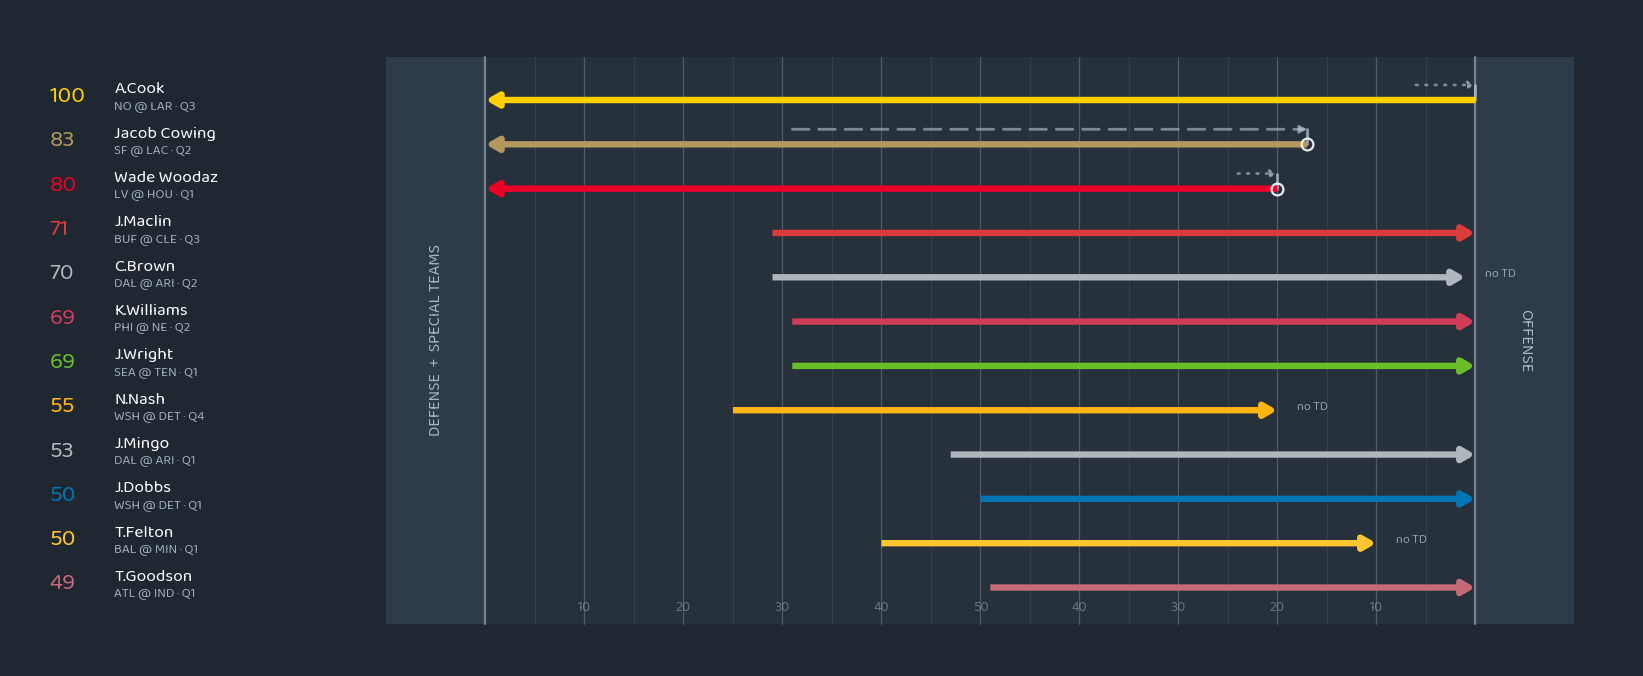

In [19]:
for i, p in enumerate(PLAYS):
    y = i * LANE_H
    fill = pick_color(p["team_colors"])
    draw_play(p, y, fill)
    ax.text(-44, y, str(p["yardage"]), ha="left", va="center",
            fontsize=17, fontweight="bold", color=fill)
    ax.text(-37.5, y - 0.16, p["player"], ha="left", va="center",
            fontsize=12.5, fontweight="bold", color=WHITE)
    ax.text(-37.5, y + 0.22, f'{p["game_name"]} · Q{p["quarter"]}',
            ha="left", va="center", fontsize=9.5, color=MUTED, alpha=0.85)
    if not p["touchdown"]:
        ax.text(p["segments"][-1]["to"] + 2.0, y, "no TD", ha="left", va="center",
                fontsize=9, color=MUTED, alpha=0.75, fontstyle="italic")
fig

## 8. Legend

Built from `Line2D` proxies because none of the real artists are labelled — the arrows are
`FancyArrowPatch` objects drawn in a loop, and labelling them would produce twelve
entries, one per play.

`bbox_to_anchor` is in **axes fractions**, not data coordinates, and the x-axis runs -46 to
114 to accommodate the label gutter. So `0.302` lands at roughly the goal line;
`0.085` would put the legend on top of the player labels. Worth recomputing if `xlim`
ever changes.

Placement caveat: this parks the legend over the 10-to-30 range on the bottom three rows.
It's clear this week only because those three plays all start at the 40 or beyond. For a
weekly build, move it to a fixed panel below the field.

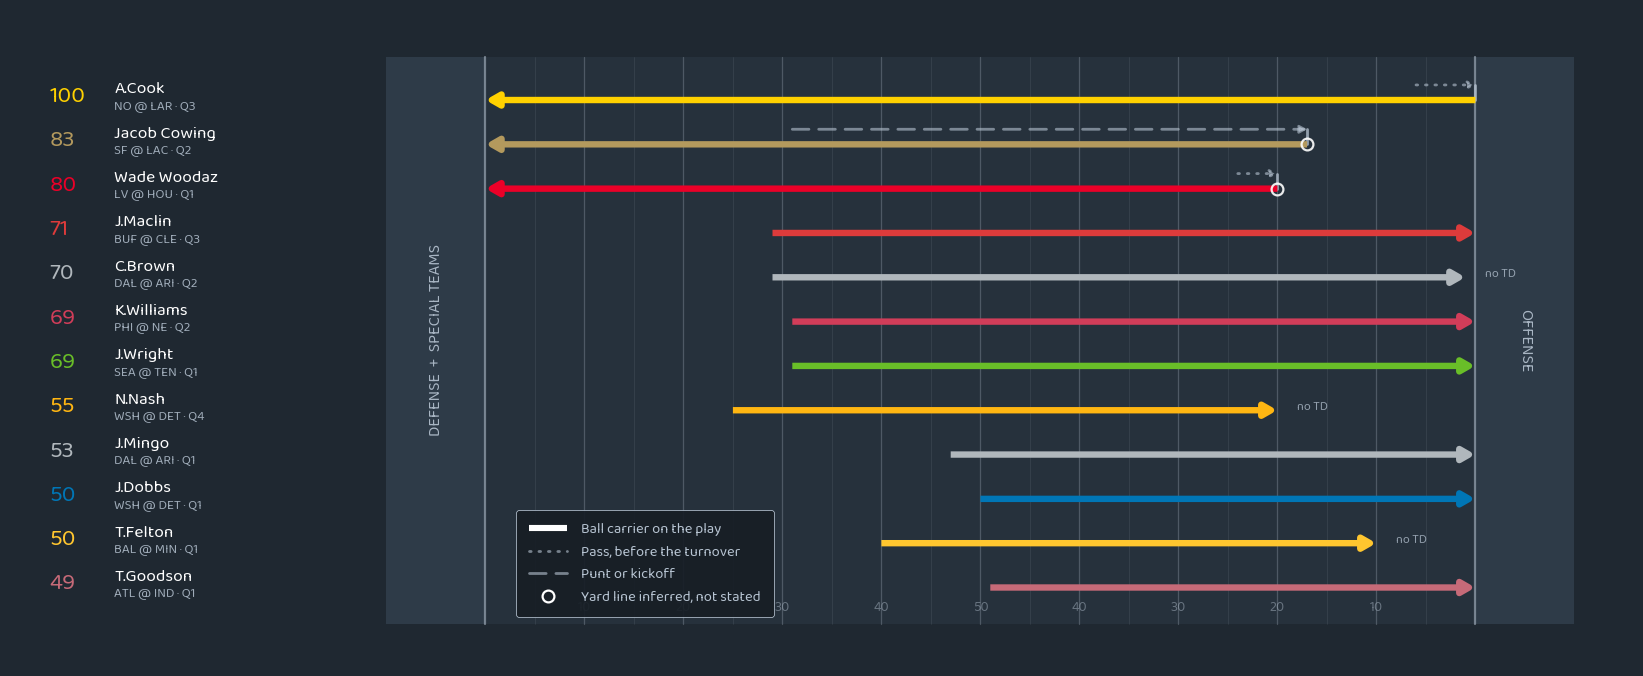

In [20]:
handles = [
    Line2D([], [], color=WHITE, lw=4.4, solid_capstyle="butt",
           label="Ball carrier on the play"),
    Line2D([], [], color=MUTED, lw=2.0, alpha=0.6, linestyle=DOTTED,
           dash_capstyle="round", label="Pass, before the turnover"),
    Line2D([], [], color=MUTED, lw=2.0, alpha=0.6, linestyle=DASHED,
           label="Punt or kickoff"),
    Line2D([], [], color="none", marker="o", ms=8.5, mfc="none",
           mec=WHITE, mew=1.6, label="Yard line inferred, not stated"),
]
leg = ax.legend(handles=handles, loc="lower left",
                bbox_to_anchor=(0.302, 0.035), frameon=True,
                facecolor="#171E25", edgecolor=MUTED, framealpha=0.92,
                fontsize=10.5, labelcolor=MUTED, borderpad=0.9,
                labelspacing=0.65, handlelength=2.6, handletextpad=1.0)
leg.get_frame().set_linewidth(0.6)
leg.set_zorder(8)
fig

## 9. Titles and export

Titles go on the **figure**, not the axes, so they centre on the full 1600px width rather
than on the field rectangle — which is offset right by the label gutter.

No engagement caption and no programmatic watermark: the `@dataglazer` mark is added by
hand after export.

The last two lines are the important bit. `savefig.bbox: tight` in the style file
overrides whatever you pass to `savefig`, cropping to the drawn content and producing
unpredictable pixel dimensions. Forcing `"standard"` first is what makes the output
exactly 1600×800.

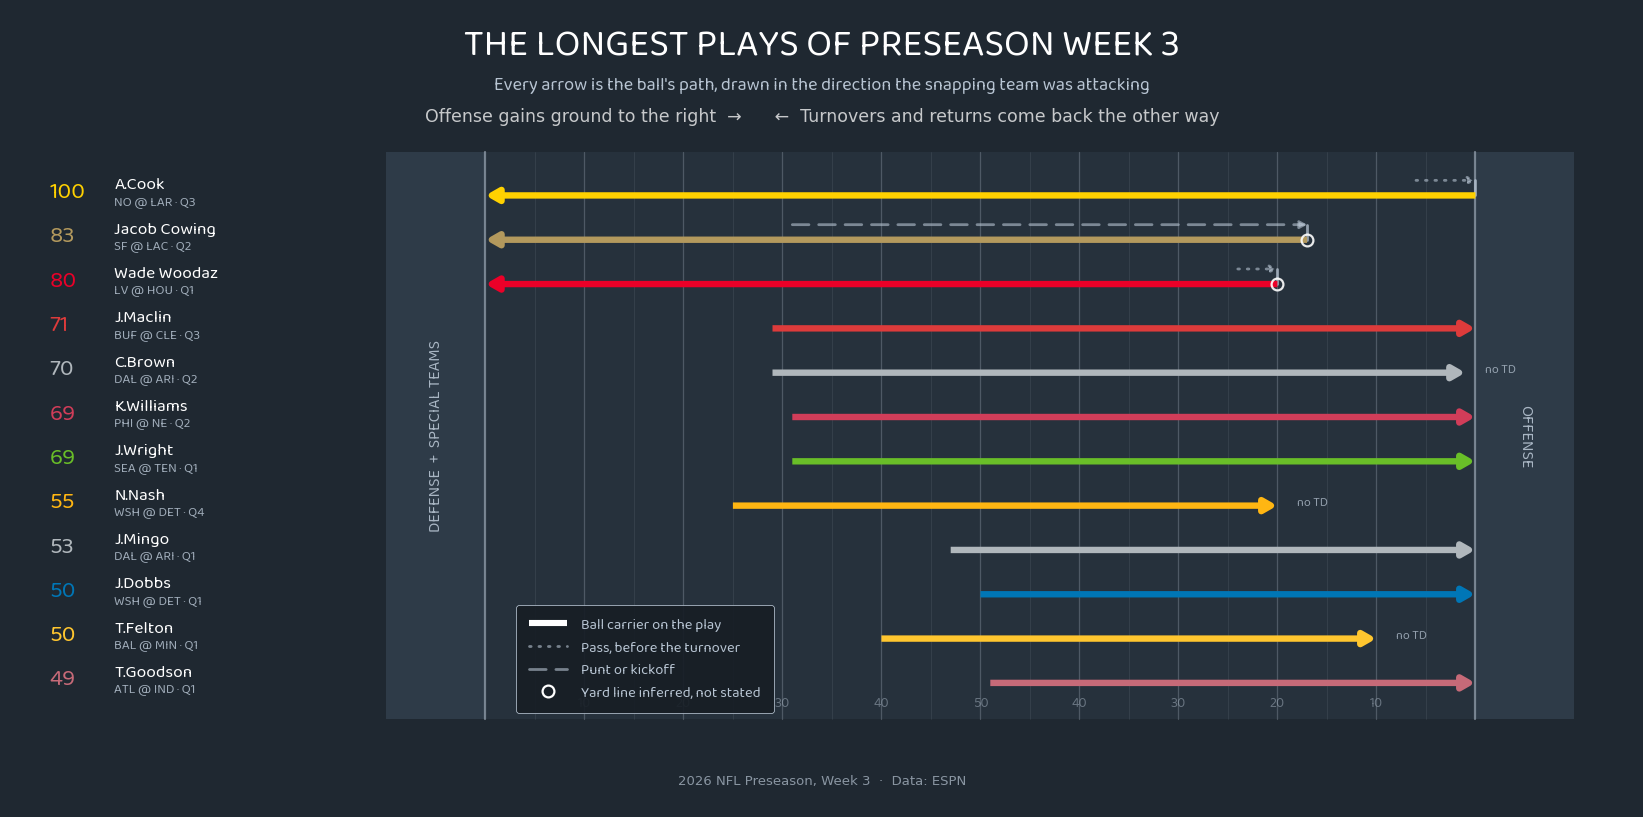

In [ ]:
fig.text(0.5, 0.965, "THE LONGEST PLAYS OF PRESEASON WEEK 3",
         ha="center", va="top", fontsize=27, fontweight="bold", color=WHITE)
fig.text(0.5, 0.905,
         "Every arrow is the ball's path, drawn in the direction the snapping team was attacking",
         ha="center", va="top", fontsize=13, color=MUTED)
# arrows and the ring glyph are absent from Poppins, so this line forces DejaVu
fig.text(0.5, 0.868,
         "Offense gains ground to the right  →      ←  Turnovers and returns come back the other way",
         ha="center", va="top", fontsize=12.5, color=WHITE, alpha=0.75,
         fontfamily="DejaVu Sans")
fig.text(0.5, 0.018, "2026 NFL Preseason, Week 3  ·  Data: ESPN",
         ha="center", va="bottom", fontsize=9.5, color=MUTED, alpha=0.7,
         fontfamily="DejaVu Sans")


fig

In [22]:
from dataglazer_nfl.config import FIGURES_DIR

out = FIGURES_DIR / "week3-big-plays-field-map.png"
plt.rcParams["savefig.bbox"] = "standard"     # beats the style file's "tight"
fig.savefig(out, dpi=100, facecolor=BG)